# Lesson 2 - Exercise 1: Quantifying KV Cache Memory Growth: Krithika's Solution
As per the Udacity Starter Code , this only measures the peak memory. It doesnt really do anything specifically for KV cache

**Goal:** Empirically measure and analyze the growth in peak GPU memory consumption during LLM inference as the number of generated tokens increases, thereby quantifying the memory footprint of the Key-Value (KV) Cache.

## 2. Imports and Configuration

### KSW Notes : Generation Length vs KV Cache
KV Cache grows with Total Sequence Length \
Total Sequence Length = Input Prompt Length + Generated Token Length (generation length) \
When you set the generation length = 50, you are setting the max generated tokesn to 50. \
But the output might not warrant 50 tokens. Example the output of what is 2+2 .The answer is 4, which might be just 1-2 tokens. \
And if the output doesnt consume all the generation length tokens in , the kv cache will not grow as expected
generation_lengths = [10, 20, 30, 50, 100, 200, 500]

### KV cache Memory formula
M_KV=2 * L *B *T * H_{kv} *D_h * S

1. KV cache memory formula
- L   : Number of transformer layers
- B   : Batch size
- T   : Total sequence length
- H_kv: Number of KV heads
- D_h :	Head dimension
- S   :	Bytes per element
- 2	   : Key cache + Value cache


In [7]:
import os
import torch
import time
from transformers import AutoModelForCausalLM, AutoTokenizer
import gc # For garbage collection
import matplotlib.pyplot as plt

# --- Configuration ---
'''
os.environ["HF_HUB_OFFLINE"] = "1"
model_name = "/voc/shared/models/llama/Llama-3.2-1B"
'''

model_name = "Qwen/Qwen2.5-0.5B"


device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    print("WARNING: This exercise requires a CUDA-enabled GPU for meaningful memory measurements. Results on CPU will not reflect KV cache growth on GPU.")

# TODO: Determine appropriate dtype
if device == "cuda":
    if torch.cuda.is_bf16_supported():
        dtype = torch.bfloat16
        print("Using torch.bfloat16")
    else:
        dtype = torch.float16
        print("Using torch.float16 (bf16 not supported)")
else:
    dtype = torch.float32 # Default for CPU
    print("Using torch.float32 for CPU")

prompt = "The best way to optimize LLM inference is"

# TODO: Define a list of different max_new_tokens values to test.
generation_lengths = [10, 20, 30, 50, 100, 200, 500, 1000,2000]

print(f"Device: {device}")
print(f"Model: {model_name}")
print(f"Prompt: '{prompt}'")
print(f"Generation lengths to test: {generation_lengths}")

Using torch.bfloat16
Device: cuda
Model: Qwen/Qwen2.5-0.5B
Prompt: 'The best way to optimize LLM inference is'
Generation lengths to test: [10, 20, 30, 50, 100, 200, 500, 1000, 2000]


## 3. Helper Function to Measure Peak Memory

In [8]:
def get_peak_gpu_memory_mb(device_to_check="cuda"):
    """Records the peak GPU memory allocated since the last reset for the specified device."""
    if torch.cuda.is_available() and device_to_check == "cuda":
        torch.cuda.synchronize() # Ensure all CUDA operations are complete
        # TODO: check the documentation https://docs.pytorch.org/docs/stable/cuda.html for function that can give peak memory
        peak_mem_bytes = torch.cuda.max_memory_allocated(device_to_check)
        return peak_mem_bytes / (1024 * 1024) # Convert to MB
    return 0 # Return 0 if not on CUDA or for CPU

## 4. Load Model and Tokenizer

In [9]:
print(f"\nLoading model and tokenizer for {model_name}...")
try:
    # TODO-Done: Load the tokenizer using AutoTokenizer.from_pretrained()
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    
    # TODO-Done: Set tokenizer.pad_token if it's None (e.g., tokenizer.pad_token = tokenizer.eos_token)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    # TODO-Done: Load the model using AutoModelForCausalLM.from_pretrained()
    #       Specify torch_dtype=dtype and attn_implementation="sdpa"
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        torch_dtype=dtype,
        trust_remote_code=False,
        low_cpu_mem_usage=True,
        attn_implementation="sdpa"
    )

    #TODO-Done: Move the model to the specified device (.to(device))
    model.to(device)

    # TODO-Done: Set the model to evaluation mode using model.eval()
    model.eval()

    print("Model and tokenizer loaded successfully.")
except Exception as e:
    print(f"Error loading model/tokenizer: {e}")
    # exit() # Consider exiting if loading fails


Loading model and tokenizer for Qwen/Qwen2.5-0.5B...
Model and tokenizer loaded successfully.


## 5. Test Configuration & Measurement Loop
## 6. Deliverables: Analysis and Reporting

In [10]:
def run_and_plot_for_varied_lengths(use_cache = True):

    if use_cache:
        use_cache_string = '(Use KV Cache = True)'
    else :
        use_cache_string = '(Use KV Cache = False)'
    
    peak_memory_results_mb = []
    actual_tokens_generated_list = []
    generation_times = []
    
    print("\n--- Measuring KV Cache Memory Growth",use_cache_string ,"---")
    
    if device == "cuda" and model is not None: # Proceed only if model loaded and on CUDA
        # Initial memory measurement (model loaded, no generation yet). model.to(device) has already has loaded the model
        # Reset before taking baseline
        gc.collect()
        torch.cuda.empty_cache()        
        # resets the peak to the memory currently allocated (not to zero). So it contains the memory for the model weights
        torch.cuda.reset_peak_memory_stats(device)
        torch.cuda.synchronize(device)
        initial_peak_memory_mb = get_peak_gpu_memory_mb(device)
        print(f"Initial peak memory (model loaded on GPU): {initial_peak_memory_mb:.2f} MB")
    
        # This will measure model weights + forward-pass temporary memory, without autograd graph memory or KV cache storage.
        with torch.no_grad():
            _ = model(torch.tensor([[0]], device=device)) # Dummy forward pass to ensure model is fully on GPU
        torch.cuda.synchronize(device)
        one_forward_pass_peak_memory_mb = get_peak_gpu_memory_mb(device)
        print(f" Peak memory after 1 forward pass (model loaded on GPU+ 1 forward pass): {one_forward_pass_peak_memory_mb :.2f} MB")
        del _
    
        # TODO-Done: Tokenize the prompt using the loaded tokenizer.
        #       Ensure tensors are moved to the correct device.
        # Tokenize once: same prompt for all experiments
        inputs = tokenizer(prompt, return_tensors="pt").to(device)
        # TODO-Done:  Get the number of tokens in the input prompt
        # inputs is a dict. input_ids is of the shape [batch_size, total_sequence_length]
        # So get the shape off input_ids not inputs
        num_input_tokens = inputs["input_ids"].shape[1]
        
        for length in generation_lengths:
            print(f"\nGenerating {length} new tokens...")
            
            if inputs is None:
                print("  Skipping due to uninitialized inputs.",use_cache_string ,"---")
                peak_memory_results_mb.append(float('nan'))
                actual_tokens_generated_list.append(0)
                generation_times.append(float('nan'))
                continue
    
            # TODO-Done: Reset GPU memory stats before this specific generation run
            gc.collect()
            torch.cuda.empty_cache()        
            torch.cuda.reset_peak_memory_stats(device)      
            torch.cuda.synchronize(device)
            
            start_time = time.perf_counter()
            with torch.no_grad():
                try:
                    # TODO-Done: Generate tokens using model.generate()
                    #       - Pass inputs["input_ids"]
                    #       - Set max_new_tokens=length
                    #       - Ensure use_cache=True (it's usually default but good to be explicit)
                    #       - Set pad_token_id=tokenizer.pad_token_id
                    output_ids = model.generate(inputs["input_ids"],
                                            max_new_tokens = length,
                                            use_cache = use_cache,
                                            pad_token_id=tokenizer.pad_token_id)
    
                    if output_ids is None:
                        raise ValueError("Outputs from model.generate() is None.")
    
                    # TODO-Done: Calculate actual number of new tokens generated                
                    # tokens in the output. output_ids is of the shape [batch_size, total_sequence_length]
                    num_output_tokens = output_ids.shape[1]
                    actual_new_tokens = num_output_tokens - num_input_tokens
                    actual_tokens_generated_list.append(actual_new_tokens)
    
                except Exception as e:
                    print(f"  Error during generation for length {length}: {e}")                 
                    actual_tokens_generated_list.append(0)
                    generation_times.append(float('nan'))
                    peak_memory_results_mb.append(float('nan'))
                    continue
    
            # TODO-Done: Synchronize CUDA operations before recording memory and time
            torch.cuda.synchronize(device)
            end_time = time.perf_counter()
            gen_time = end_time - start_time
            generation_times.append(gen_time)
    
            # TODO-Done: Record peak GPU memory allocated during THIS generation run
            current_peak_memory_mb = get_peak_gpu_memory_mb(device)
            peak_memory_results_mb.append(current_peak_memory_mb)
    
            print(f"  Actual new tokens generated: {actual_new_tokens}")
            print(f"  Peak memory allocated for this generation: {current_peak_memory_mb:.2f} MB")
            print(f"  Generation time: {gen_time:.4f} seconds")
    
            # Cleanup
            del output_ids
        # Clean up at the end of the for loop
        del inputs
        gc.collect()
        torch.cuda.empty_cache()        
        torch.cuda.reset_peak_memory_stats(device)      
        torch.cuda.synchronize(device)
    
    else:
        print("Skipping measurement loop: Model not loaded or not on CUDA device.")
    
    ## 6. Deliverables: Analysis and Reporting
    
    print("\n--- Results Summary",use_cache_string ,"---")
    print("Max New Tokens | Actual New Tokens | Peak Memory (MB) during Gen | Time (s)")
    print("---------------|-------------------|-----------------------------|----------")
    for i, requested_length in enumerate(generation_lengths):
        if i < len(peak_memory_results_mb) and i < len(actual_tokens_generated_list) and i < len(generation_times):
            actual_len = actual_tokens_generated_list[i]
            mem_val = peak_memory_results_mb[i]
            time_val = generation_times[i]
            print(f"{requested_length:15} | {actual_len:17} | {mem_val:27.2f} | {time_val:8.4f}")
        else:
            # This case handles if a generation run failed and wasn't recorded
            print(f"{requested_length:15} | {'N/A':17} | {'N/A':27} | {'N/A':8}")
    
    # TODO: Trend Analysis:
    # 1. Describe the relationship you observe between 'Actual New Tokens' and 'Peak Memory (MB) during Gen'.
    #    Is it linear? Does it increase as expected?
    #    (You can also consider 'Peak Memory (MB) during Gen' - initial_peak_memory_mb to see the growth above the model size).
    
    # TODO: Estimate Memory per Token:
    # 2. Calculate an estimate of how much *additional* memory the KV cache consumes per *actually generated new token*.
    #    - Select two data points from your results (e.g., generation for 50 tokens and 150 tokens).
    #    - Calculate ΔMemory = PeakMemory_LongerRun - PeakMemory_ShorterRun
    #    - Calculate ΔTokens = ActualTokens_LongerRun - ActualTokens_ShorterRun
    #    - Estimate MemoryPerToken = ΔMemory / ΔTokens (if ΔTokens > 0)
    #    - Print your chosen data points and the calculated memory per token.
    
    # TODO: Practical Impact Discussion:
    # 3. Briefly discuss how this growing KV cache memory footprint can become a limiting factor for generating 
    #    very long sequences, especially on GPUs with constrained VRAM. How does this relate to the concept 
    #    of "context window limits" in practice (even if the model theoretically supports a large window)?
    
    # --- Plotting ---
    if device == "cuda" and any(m > 0 for m in peak_memory_results_mb if isinstance(m, (int, float)) and not torch.isnan(torch.tensor(m))):
        # Filter out NaN or non-numeric before plotting
        valid_indices = [i for i, mem in enumerate(peak_memory_results_mb) 
                         if isinstance(mem, (int, float)) and not torch.isnan(torch.tensor(mem))]
        plot_lengths = [actual_tokens_generated_list[i] for i in valid_indices]
        plot_memory = [peak_memory_results_mb[i] for i in valid_indices]
        
        if plot_lengths and plot_memory and len(plot_lengths) == len(plot_memory):
            try:
                plt.figure(figsize=(10, 6))
                plt.plot(plot_lengths, plot_memory, marker='o', linestyle='-')
                plt.title(f'Peak GPU Memory vs. Number of Actual New Tokens Generated\nModel: {model_name}, {use_cache_string}')
                plt.xlabel('Number of Actual New Tokens Generated')
                plt.ylabel('Peak GPU Memory Allocated During Generation (MB)')
                plt.grid(True)
                # plt.xticks(plot_lengths) # May be too crowded if many points
                plt.tight_layout()
                plot_filename = "kv_cache_memory_growth.png"
                #plt.savefig(plot_filename)
                print(f"\nPlot saved to {plot_filename}")
                plt.show()
            except Exception as e:
                print(f"Could not generate plot: {e}. Ensure matplotlib is installed.")
        else:
            print("Not enough valid data points to plot.",use_cache_string ,"---")
    elif device != "cuda":
        print("\nPlotting is designed for CUDA memory measurements.",use_cache_string ,"---")
    
    print("\nExercise Complete. ",use_cache_string ,"---")

## 7a. Run and Plot for Different Generation LEngths: Use_Cache = use_kv_cache = True


--- Measuring KV Cache Memory Growth (Use KV Cache = True) ---
Initial peak memory (model loaded on GPU): 958.49 MB
 Peak memory after 1 forward pass (model loaded on GPU+ 1 forward pass): 959.52 MB

Generating 10 new tokens...
  Actual new tokens generated: 10
  Peak memory allocated for this generation: 960.45 MB
  Generation time: 0.0929 seconds

Generating 20 new tokens...
  Actual new tokens generated: 20
  Peak memory allocated for this generation: 960.56 MB
  Generation time: 0.2004 seconds

Generating 30 new tokens...
  Actual new tokens generated: 30
  Peak memory allocated for this generation: 960.68 MB
  Generation time: 0.3015 seconds

Generating 50 new tokens...
  Actual new tokens generated: 50
  Peak memory allocated for this generation: 960.92 MB
  Generation time: 0.5064 seconds

Generating 100 new tokens...
  Actual new tokens generated: 100
  Peak memory allocated for this generation: 961.50 MB
  Generation time: 0.9839 seconds

Generating 200 new tokens...
  Actual

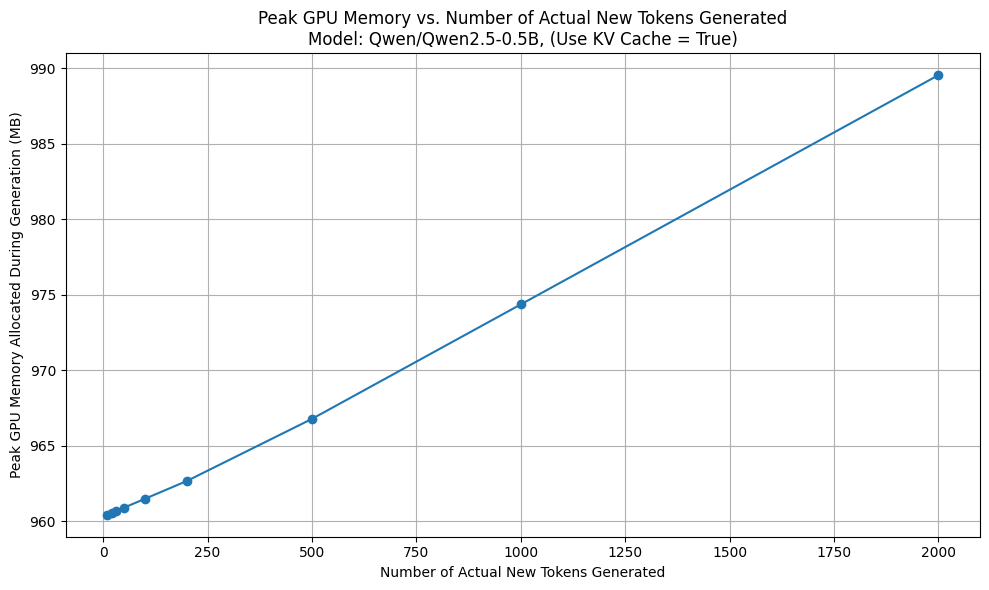


Exercise Complete.  (Use KV Cache = True) ---


In [11]:
run_and_plot_for_varied_lengths(use_cache = True)

## 7b. Run and Plot for Different Generation LEngths: Use_Cache = use_kv_cache = False


--- Measuring KV Cache Memory Growth (Use KV Cache = False) ---
Initial peak memory (model loaded on GPU): 958.49 MB
 Peak memory after 1 forward pass (model loaded on GPU+ 1 forward pass): 959.52 MB

Generating 10 new tokens...
  Actual new tokens generated: 10
  Peak memory allocated for this generation: 960.24 MB
  Generation time: 0.0978 seconds

Generating 20 new tokens...
  Actual new tokens generated: 20
  Peak memory allocated for this generation: 960.29 MB
  Generation time: 0.2009 seconds

Generating 30 new tokens...
  Actual new tokens generated: 30
  Peak memory allocated for this generation: 960.40 MB
  Generation time: 0.3020 seconds

Generating 50 new tokens...
  Actual new tokens generated: 50
  Peak memory allocated for this generation: 961.10 MB
  Generation time: 0.5103 seconds

Generating 100 new tokens...
  Actual new tokens generated: 57
  Peak memory allocated for this generation: 961.35 MB
  Generation time: 0.5858 seconds

Generating 200 new tokens...
  Actual

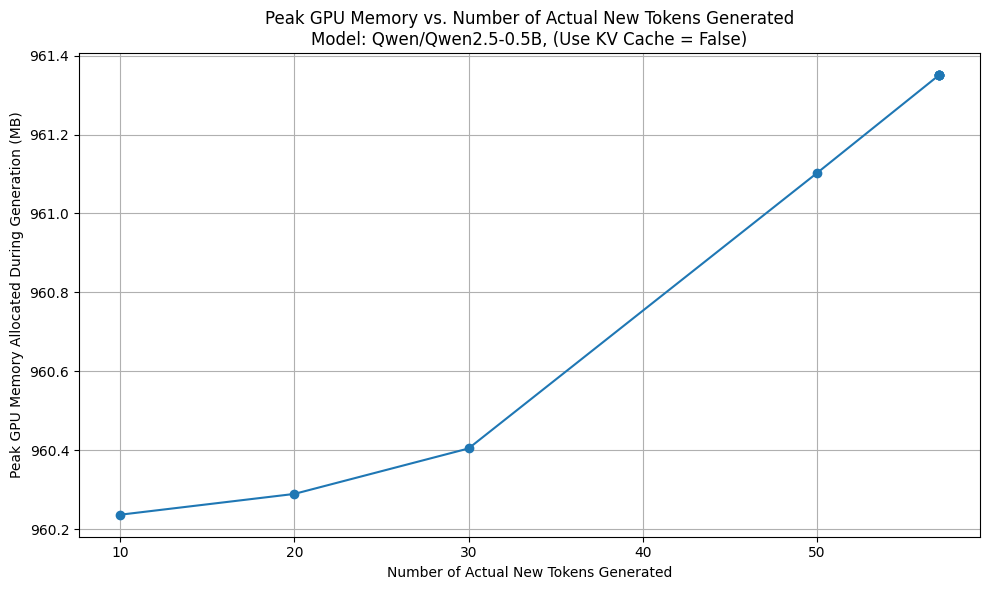


Exercise Complete.  (Use KV Cache = False) ---


In [12]:
run_and_plot_for_varied_lengths(use_cache = False)

### Trend Analysis: IUse Cache = True

**TODO-Done: Trend Analysis:** \
**Question1:** Describe the relationship you observe between 'Actual New Tokens' and 'Peak Memory (MB) during Gen'. \
Is it linear? Does it increase as expected? \
(You can also consider 'Peak Memory (MB) during Gen' - initial_peak_memory_mb to see the growth above the model size). \
**Answer:** Yes it is Linear


**TODO-Done: Estimate Memory per Token:**\
**Question2:** Calculate an estimate of how much *additional* memory the KV cache consumes per *actually generated new token*.
    - Select two data points from your results (e.g., generation for 50 tokens and 150 tokens).
    - Calculate ΔMemory = PeakMemory_LongerRun - PeakMemory_ShorterRun
    - Calculate ΔTokens = ActualTokens_LongerRun - ActualTokens_ShorterRun
    - Estimate MemoryPerToken = ΔMemory / ΔTokens (if ΔTokens > 0)
    - Print your chosen data points and the calculated memory per token.
**Answer:** \

--- Results Summary ---\


Max New Tokens  | Actual New Tokens | Peak Memory (MB) during Gen | Time (s)
--------------  | ----------------- | --------------------------  | ---------
             10 |                10 |                      960.26 |   0.1584
             20 |                20 |                      960.38 |   0.1811
             30 |                30 |                      960.49 |   0.2724
             50 |                50 |                      960.73 |   0.4507
            100 |               100 |                      961.32 |   0.8984
            200 |               200 |                      962.49 |   1.7980
            500 |               500 |                      966.60 |   4.6042
           1000 |              1000 |                      974.18 |   9.3464
           2000 |              2000 |                      989.35 |  19.6402

Token range	| ΔMemory   | ΔTokens | Memory/token
------------|-----------|---------|------------
10–500      | 6.34 MB   |	490   | 13.25 KiB
500–2000	| 22.75 MB  |  1500	  | 15.53 KiB


Interesting observation: The estimated memory per token is slightly higher for the longer generation range.\
This could reflect changes in cache allocation, memory alignment, or other temporary GPU allocations.\
It does not necessarily mean that the theoretical KV-cache size per token increases with sequence length.\
For a standard Transformer KV cache, memory per cached token is expected to remain approximately constant, even though total KV-cache memory grows linearly.


           
**TODO-Done: Practical Impact Discussion:**\
**Question3:** Briefly discuss how this growing KV cache memory footprint can become a limiting factor for generating  very long sequences, especially on GPUs with constrained VRAM. How does this relate to the concept of "context window limits" in practice (even if the model theoretically supports a large window)? \
**Answer:** \
Essentially : GPU Out of Memory (OOM) is the main concern. \
As the number of generated tokens increases, the KV cache grows, consuming more GPU memory. On GPUs with limited VRAM, this can eventually cause an Out of Memory (OOM) error. Therefore, even if a model theoretically supports a large context window, the available GPU memory may limit how many tokens can actually be processed or generated. \
One additional distinction:
- Theoretical context window: The maximum number of tokens the model is designed to handle.
- Practical context window: The number of tokens you can actually process given your GPU's available VRAM and inference configuration.
Remember that the context window includes both input prompt tokens and generated output tokens.